Install necessary packages

In [1]:
import os
os.environ["GCSFS_EXPERIMENTAL_ZB_HNS_SUPPORT"] = "false"

In [2]:
! pip install --upgrade xarray zarr gcsfs cftime nc-time-axis pandas

In [3]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zarr
import gcsfs

xr.set_options(display_style='html')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [4]:
plt.rcParams['figure.figsize'] = 12, 6

In [5]:
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


Our different scenarios (is what I believe we are looking for)

In [68]:
df.query("activity_id == 'ScenarioMIP'")

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
821,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,wap500,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
822,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFmon,albisccp,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
823,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,ta700,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
824,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,rsutcs,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
825,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,CFday,rsut,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
...,...,...,...,...,...,...,...,...,...,...,...
523753,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,tauv,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201
523754,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,tauu,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201
523755,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,ta,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201
523756,ScenarioMIP,MOHC,UKESM1-0-LL,ssp585,r4i1p1f2,Amon,cli,gn,gs://cmip6/CMIP6/ScenarioMIP/MOHC/UKESM1-0-LL/...,NaN,20211201


<h1>Model 1: 3 Spatial Heatmap of each level of ssp for future projections of near surface air termpature per month</h1>

activity_id == 'ScenarioMIP': Future emission scenarios.



table_id == 'Amon': Atmospheric data recorded Monthly 
- <b>Will be important when we decide for the visualization. Monthly will show us a spatial heatmap. Might be hard to put into an interactive visualization through d3. We can try to find the difference between each spatial heatmap. Might be a little bit hard.</b>
- Suggestion: If we do plan to continue with this, if possible, we should make a slider that the reader can slide through to see every month. And add a button to switch between each ssp.

variable_id == 'tas': Near-surface air temperature. 

experiment_id == 'ssp245': Represents a socioeconomic future that follows historical global trends without major shifts or extremes in technological, economic, or social development. the "middle-of-the-road" scenario.
- ssp126, ssp245, ssp585 is our different emission scenarios. In order from optimistic scenario to high-emission scenario  




In [88]:
df_ta_month_ssp126 = df.query("activity_id == 'ScenarioMIP' & table_id == 'Amon' & variable_id == 'tas' & experiment_id == 'ssp126'")
df_ta_month_ssp126

df_ta_month_ssp245 = df.query("activity_id == 'ScenarioMIP' & table_id == 'Amon' & variable_id == 'tas' & experiment_id == 'ssp245'")
df_ta_month_ssp245

df_ta_month_ssp585 = df.query("activity_id == 'ScenarioMIP' & table_id == 'Amon' & variable_id == 'tas' & experiment_id == 'ssp585'")
df_ta_month_ssp585

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
866,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,Amon,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
19008,ScenarioMIP,NOAA-GFDL,GFDL-ESM4,ssp585,r1i1p1f1,Amon,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-ES...,NaN,20180701
54625,ScenarioMIP,CNRM-CERFACS,CNRM-CM6-1,ssp585,r1i1p1f2,Amon,tas,gr,gs://cmip6/CMIP6/ScenarioMIP/CNRM-CERFACS/CNRM...,NaN,20190219
66586,ScenarioMIP,BCC,BCC-CSM2-MR,ssp585,r1i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/BCC/BCC-CSM2-MR/s...,NaN,20190314
71431,ScenarioMIP,CNRM-CERFACS,CNRM-CM6-1,ssp585,r4i1p1f2,Amon,tas,gr,gs://cmip6/CMIP6/ScenarioMIP/CNRM-CERFACS/CNRM...,NaN,20190410
...,...,...,...,...,...,...,...,...,...,...,...
523257,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r21i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210831
523268,ScenarioMIP,MRI,MRI-ESM2-0,ssp585,r2i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/MRI/MRI-ESM2-0/ss...,NaN,20210907
523318,ScenarioMIP,MRI,MRI-ESM2-0,ssp585,r4i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/MRI/MRI-ESM2-0/ss...,NaN,20210907
523403,ScenarioMIP,MRI,MRI-ESM2-0,ssp585,r5i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/MRI/MRI-ESM2-0/ss...,NaN,20210907


institution_id == 'NASA-GISS': NASA Goddard Institute for Space Studies (GISS). A climate research laboratory located in New York City
- Just picked a random institution. Feel free to see the difference between other institutions.

In [89]:
df_ta_nasa_giss_ssp126 = df_ta_month_ssp126.query("institution_id == 'NASA-GISS'")
df_ta_nasa_giss_ssp126

df_ta_nasa_giss_ssp245 = df_ta_month_ssp245.query("institution_id == 'NASA-GISS'")
df_ta_nasa_giss_ssp245

df_ta_nasa_giss_ssp585 = df_ta_month_ssp585.query("institution_id == 'NASA-GISS'")
df_ta_nasa_giss_ssp585

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
404293,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r2i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
404818,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r3i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
404922,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r2i1p3f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
404941,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r1i1p3f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405045,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r1i1p5f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405111,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r3i1p3f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405121,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r4i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405283,ScenarioMIP,NASA-GISS,GISS-E2-1-H,ssp585,r1i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405457,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r5i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405732,ScenarioMIP,NASA-GISS,GISS-E2-1-H,ssp585,r2i1p1f2,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115


If this cell under does not work, DISABLE adblocker from start up and reset!!!!

In [ ]:
# this only needs to be created once
gcs = gcsfs.GCSFileSystem(token='anon')

# get the path to a specific zarr store (the first one from the dataframe above)
zstore_month_ssp126 = df_ta_nasa_giss_ssp126.iloc[0].zstore
zstore_month_ssp245 = df_ta_nasa_giss_ssp245.iloc[0].zstore
zstore_month_ssp585 = df_ta_nasa_giss_ssp585.iloc[0].zstore

# create a mutable-mapping-style interface to the store
mapper_ssp126 = gcs.get_mapper(zstore_month_ssp126)
mapper_ssp245 = gcs.get_mapper(zstore_month_ssp245)
mapper_ssp585 = gcs.get_mapper(zstore_month_ssp585)

# open it using xarray and zarr
ds_month_ssp126 = xr.open_zarr(mapper_ssp126, consolidated=True)
ds_month_ssp245 = xr.open_zarr(mapper_ssp245, consolidated=True)
ds_month_ssp585 = xr.open_zarr(mapper_ssp585, consolidated=True)
ds_month_ssp585 # preview of the dataset

C:\Users\cryst\AppData\Local\Temp\ipykernel_10388\3570888251.py:17: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds_ssp585 = xr.open_zarr(mapper_ssp585, consolidated=True)


<xarray.Dataset> Size: 178MB
Dimensions:    (time: 3432, lat: 90, lon: 144, bnds: 2)
Coordinates:
  * time       (time) object 27kB 2015-01-16 12:00:00 ... 2300-12-16 12:00:00
  * lat        (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 85.0 87.0 89.0
  * lon        (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
    lat_bnds   (lat, bnds) float64 1kB ...
    lon_bnds   (lon, bnds) float64 2kB ...
    time_bnds  (time, bnds) object 55kB ...
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    tas        (time, lat, lon) float32 178MB ...
Attributes: (12/51)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            ScenarioMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.3.2
    ...                     ...
    table_info:             Creation Date:(21 March 2018) MD5:1fc78f7af4d0af8...
    title:                  GISS-E2-1-G output prepared for CMIP6
    tracking_id:            hdl:21.14100/f20dc809-0baa-4dbb-830d-11a4cf007346
    variable_id:            tas
    variant_label:          r2i1p1f2
    version_id:             v20200115

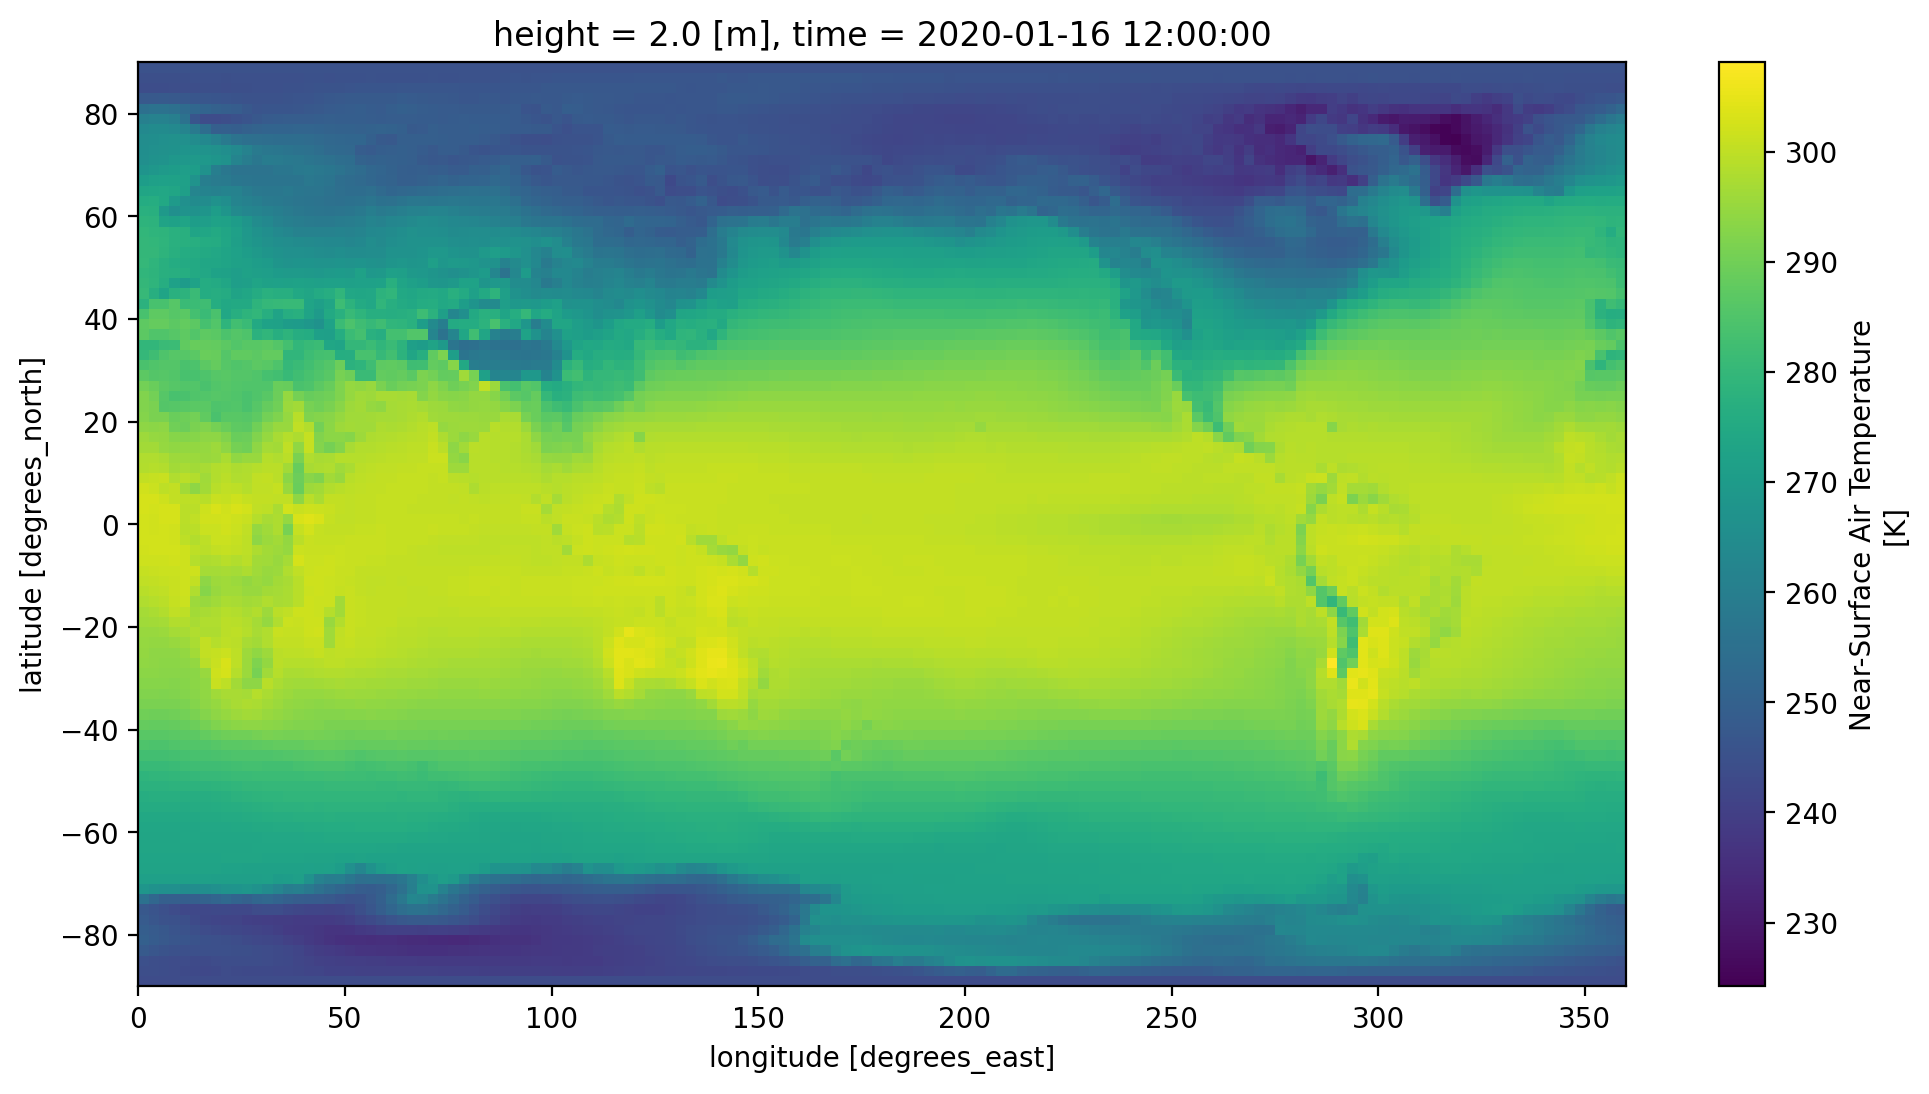

In [ ]:
ds_month_ssp126.tas.sel(time='2020-01').squeeze().plot()

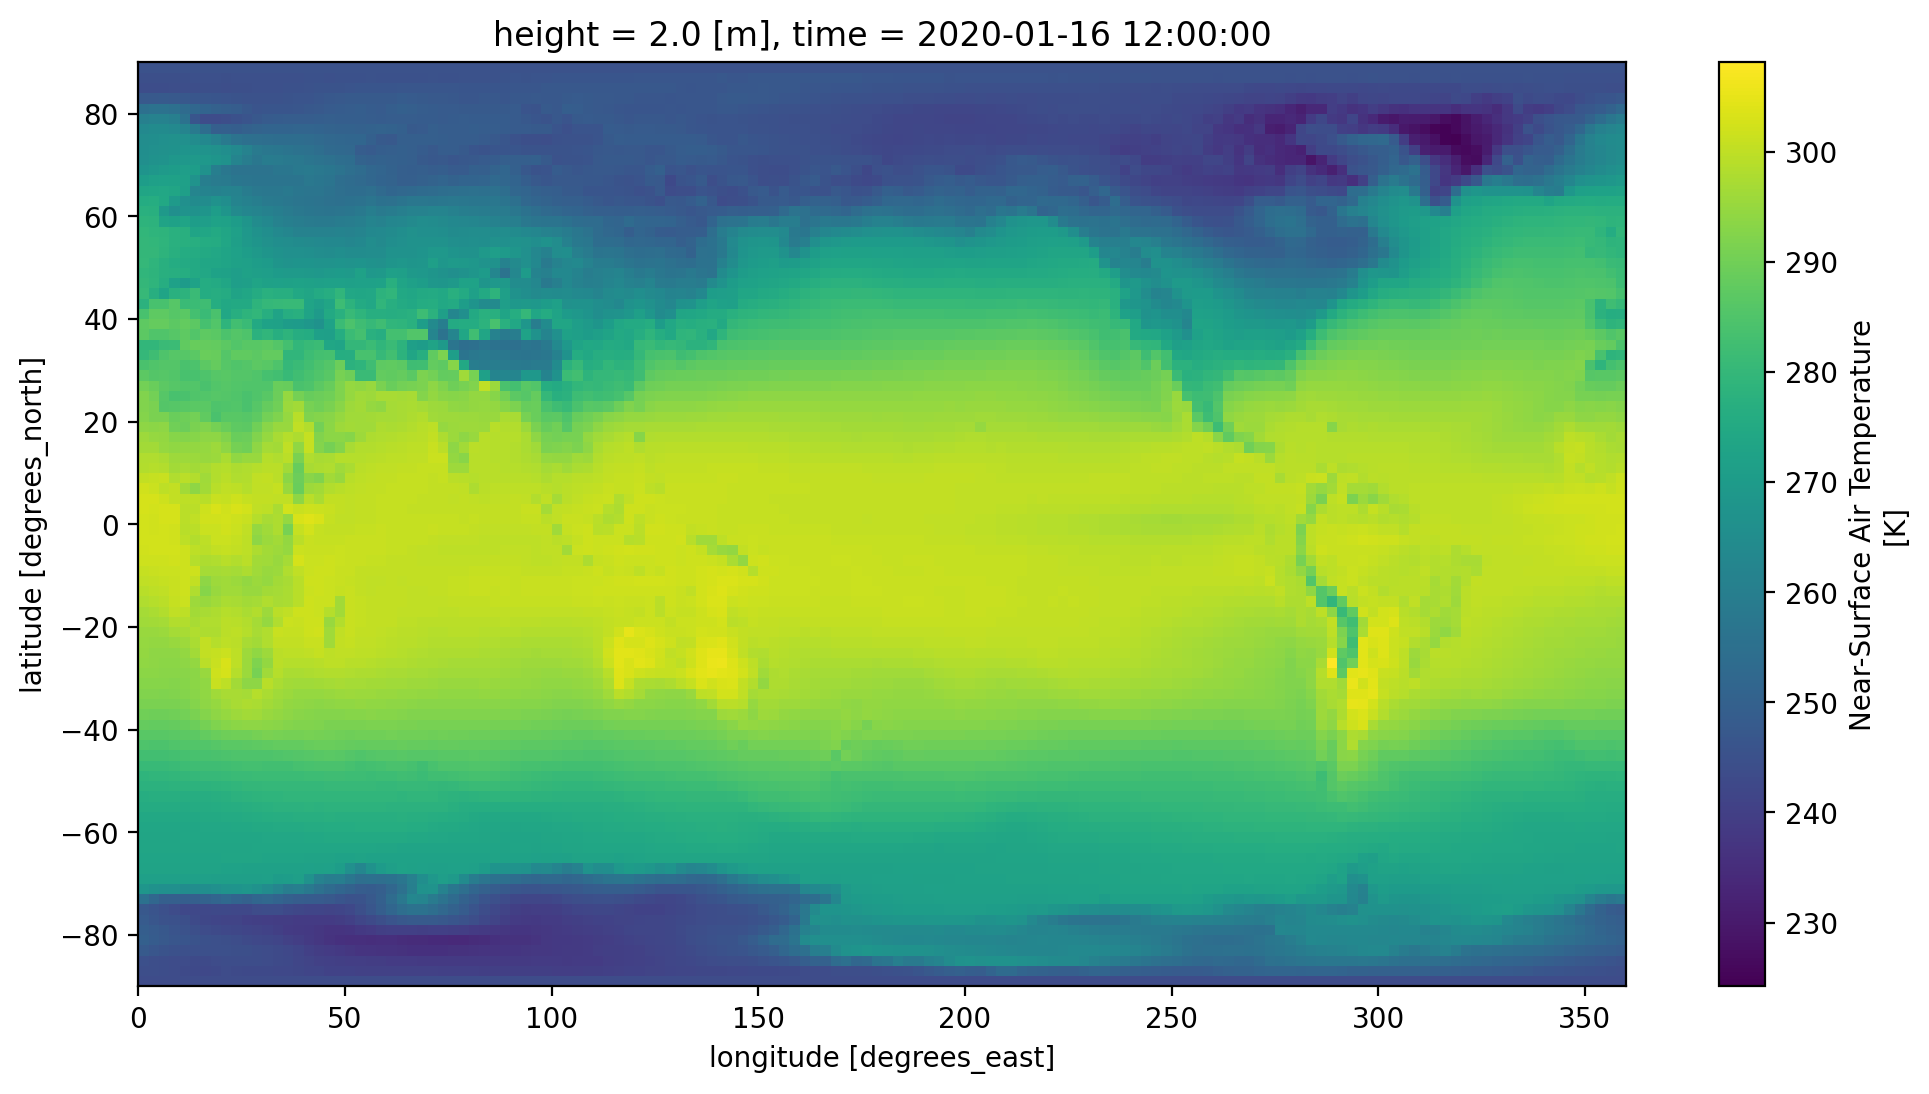

In [ ]:
ds_month_ssp126.tas.sel(time='2020-01').squeeze().plot()

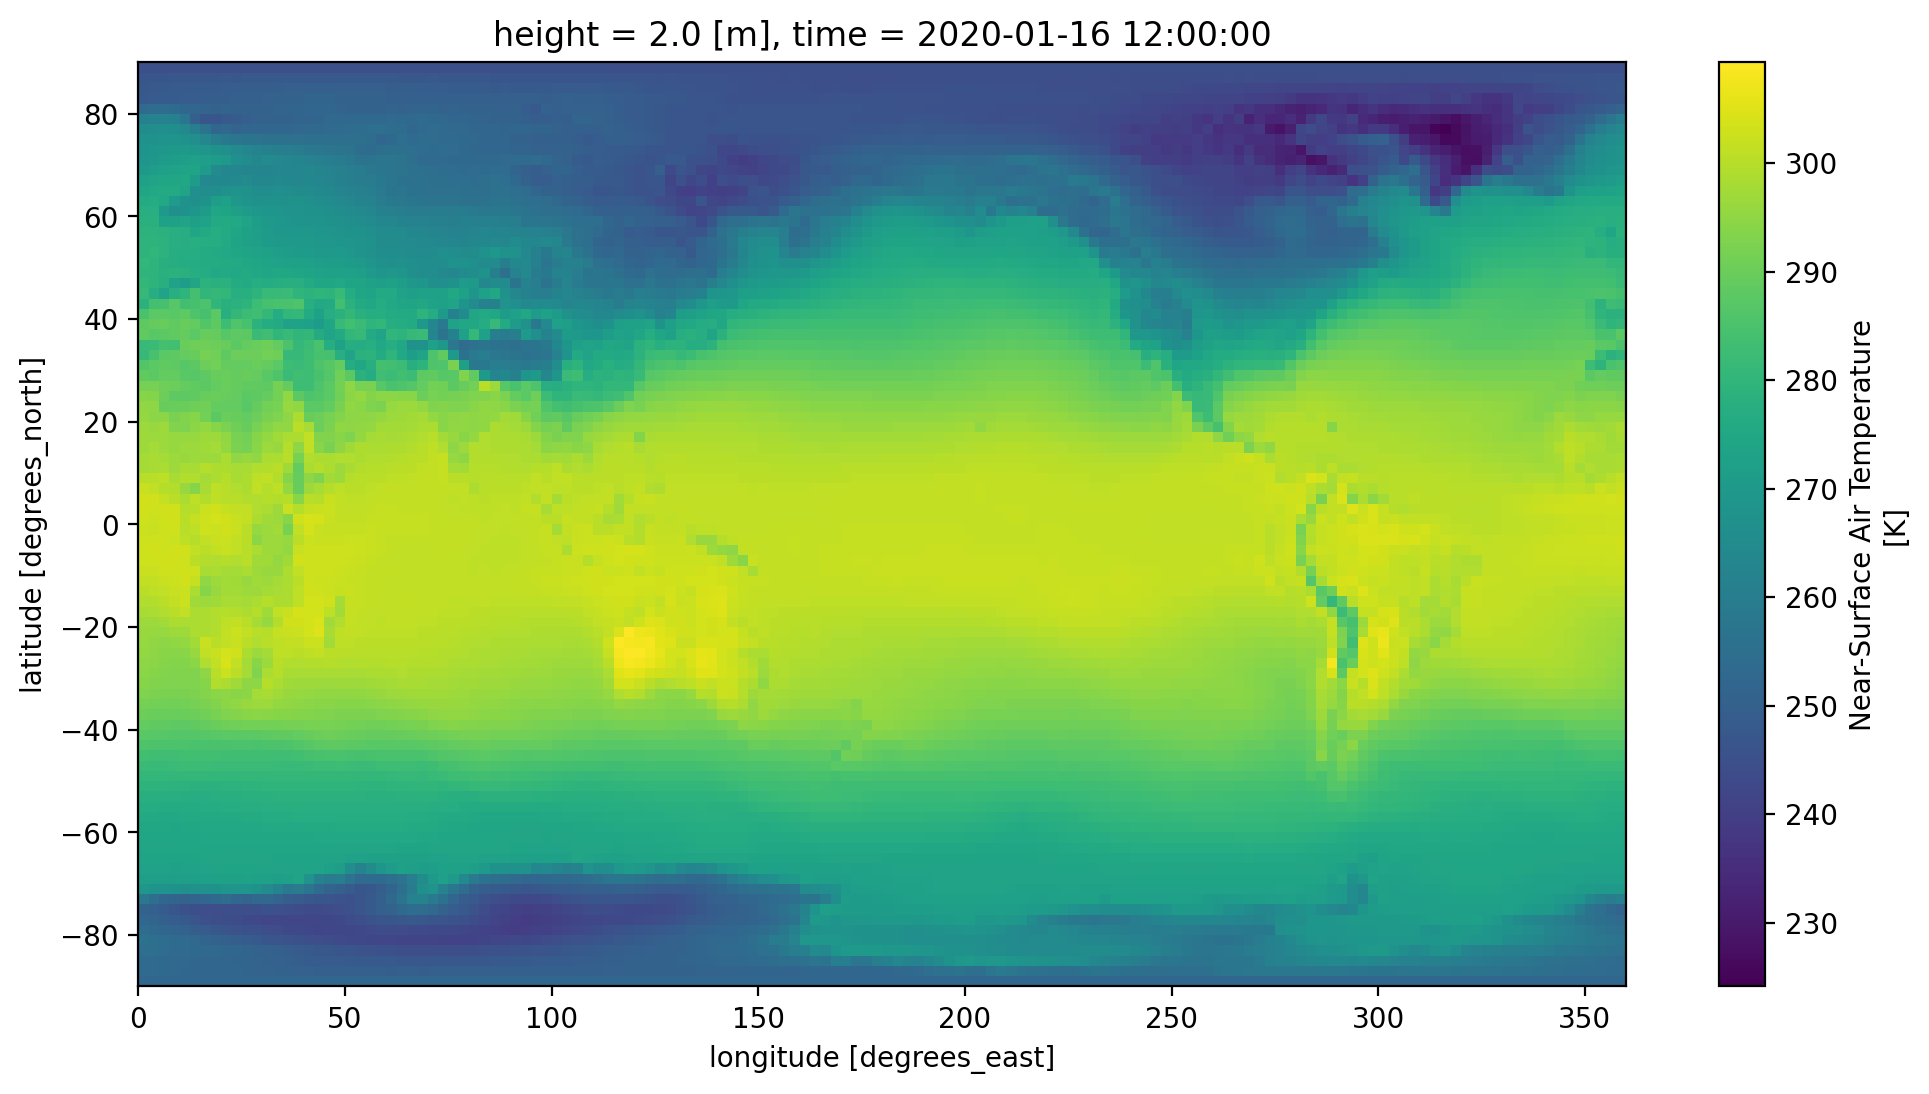

In [ ]:
ds_month_ssp245.tas.sel(time='2020-01').squeeze().plot()

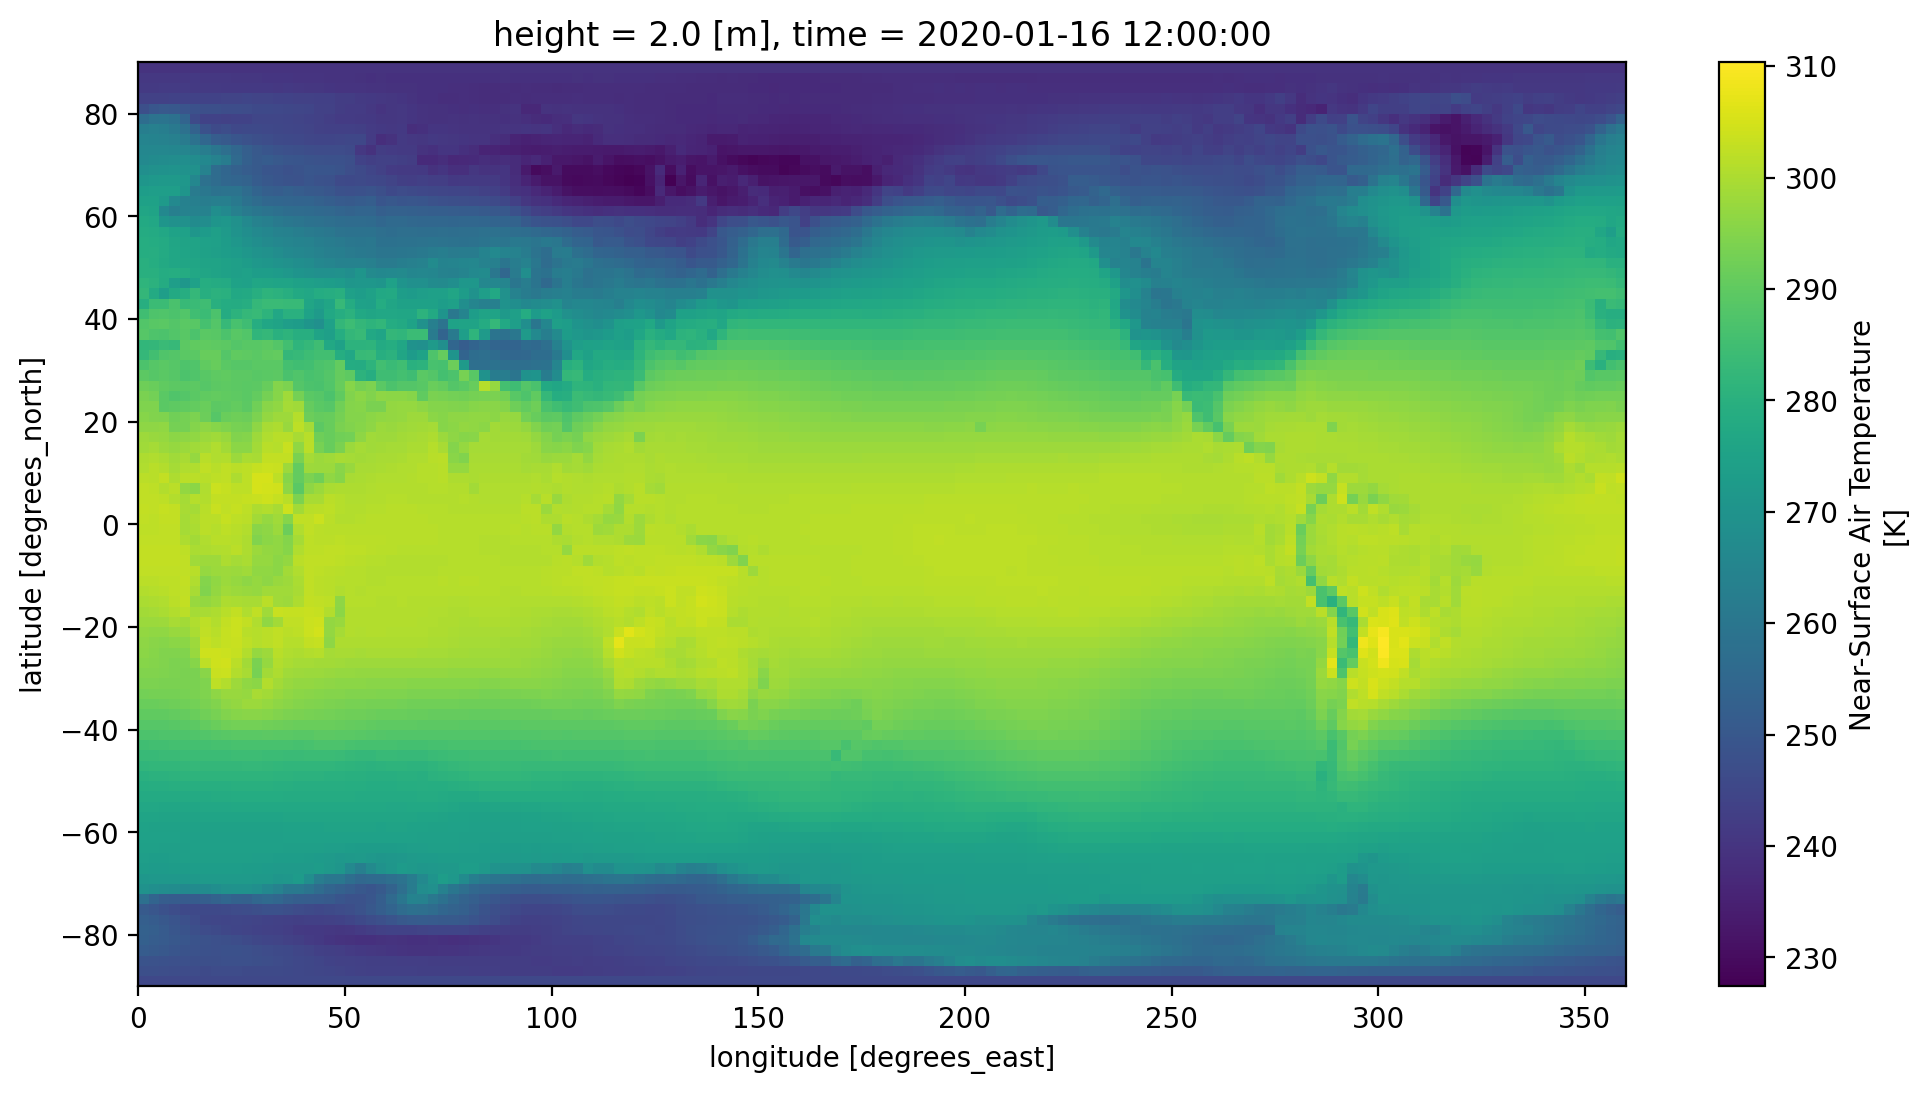

In [ ]:
ds_month_ssp585.tas.sel(time='2020-01').squeeze().plot()

There isn't that much difference between ssp126 and ssp245. But from ssp126 and ssp585, there is an apparent difference in air temperature especially in the north area. 

<b>Can help us identify what areas are affected the most from looking at these 3 models.</b>

Overall I think this is a good visualization that we can implement interactive elements to it. The problem is difficulty.

<h1>Model 2: Bar Chart of ssp245 about future projections of near surface air termpature per day</h1>

In [104]:
df_ta_day_ssp126 = df.query("activity_id == 'ScenarioMIP' & table_id == 'day' & variable_id == 'tas' & experiment_id == 'ssp126'")
df_ta_day_ssp126

df_ta_day_ssp245 = df.query("activity_id == 'ScenarioMIP' & table_id == 'day' & variable_id == 'tas' & experiment_id == 'ssp245'")
df_ta_day_ssp245

df_ta_day_ssp585 = df.query("activity_id == 'ScenarioMIP' & table_id == 'day' & variable_id == 'tas' & experiment_id == 'ssp585'")
df_ta_day_ssp585

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
11407,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,day,tas,gr2,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
11408,ScenarioMIP,NOAA-GFDL,GFDL-CM4,ssp585,r1i1p1f1,day,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-CM...,NaN,20180701
11538,ScenarioMIP,NOAA-GFDL,GFDL-ESM4,ssp585,r1i1p1f1,day,tas,gr1,gs://cmip6/CMIP6/ScenarioMIP/NOAA-GFDL/GFDL-ES...,NaN,20180701
54334,ScenarioMIP,CNRM-CERFACS,CNRM-CM6-1,ssp585,r1i1p1f2,day,tas,gr,gs://cmip6/CMIP6/ScenarioMIP/CNRM-CERFACS/CNRM...,NaN,20190219
66710,ScenarioMIP,BCC,BCC-CSM2-MR,ssp585,r1i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/BCC/BCC-CSM2-MR/s...,NaN,20190318
...,...,...,...,...,...,...,...,...,...,...,...
517941,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r9i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210318
517958,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r10i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210318
518011,ScenarioMIP,CSIRO,ACCESS-ESM1-5,ssp585,r8i1p1f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO/ACCESS-ESM1...,NaN,20210318
520066,ScenarioMIP,NIMS-KMA,UKESM1-0-LL,ssp585,r15i1p1f2,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NIMS-KMA/UKESM1-0...,NaN,20210428


In [105]:
df_ta_day_nasa_giss_ssp126 = df_ta_day_ssp126.query("institution_id == 'NASA-GISS'")
df_ta_day_nasa_giss_ssp126

df_ta_day_nasa_giss_ssp245 = df_ta_day_ssp245.query("institution_id == 'NASA-GISS'")
df_ta_day_nasa_giss_ssp245

df_ta_day_nasa_giss_ssp585= df_ta_day_ssp585.query("institution_id == 'NASA-GISS'")
df_ta_day_nasa_giss_ssp585


,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
404237,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r1i1p5f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115
405240,ScenarioMIP,NASA-GISS,GISS-E2-1-G,ssp585,r1i1p3f1,day,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2...,NaN,20200115


In [107]:
zstore_day_ssp126 = df_ta_day_nasa_giss_ssp126.iloc[0].zstore
zstore_day_ssp245 = df_ta_day_nasa_giss_ssp245.iloc[0].zstore
zstore_day_ssp585 = df_ta_day_nasa_giss_ssp585.iloc[0].zstore

# create a mutable-mapping-style interface to the store
mapper_day_ssp126 = gcs.get_mapper(zstore_day_ssp126)
mapper_day_ssp245 = gcs.get_mapper(zstore_day_ssp245)
mapper_day_ssp585 = gcs.get_mapper(zstore_day_ssp585)


# open it using xarray and zarr
ds_day_ssp126 = xr.open_zarr(mapper_day_ssp126, consolidated=True)
ds_day_ssp245 = xr.open_zarr(mapper_day_ssp245, consolidated=True)
ds_day_ssp585 = xr.open_zarr(mapper_day_ssp585, consolidated=True)


ds_day_ssp585

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 31390, lat: 90, lon: 144, bnds: 2)
Coordinates:
  * time       (time) object 251kB 2015-01-01 12:00:00 ... 2100-12-31 12:00:00
  * lat        (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 85.0 87.0 89.0
  * lon        (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
    lat_bnds   (lat, bnds) float64 1kB ...
    lon_bnds   (lon, bnds) float64 2kB ...
    time_bnds  (time, bnds) object 502kB ...
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    tas        (time, lat, lon) float32 2GB ...
Attributes: (12/49)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            ScenarioMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.3.2
    ...                     ...
    table_id:               day
    table_info:             Creation Date:(21 March 2018) MD5:d211846f9d8f448...
    title:                  GISS-E2-1-G output prepared for CMIP6
    tracking_id:            hdl:21.14100/39047456-cb48-40ea-a5c4-34535fd09b40
    variable_id:            tas
    variant_label:          r1i1p5f1

(array([   261.,   2639.,  19000.,  50260.,  37463.,  49076.,  61859.,
         58675., 120642.,   1885.]),
 array([212.90377808, 223.11994934, 233.33612061, 243.55227661,
        253.76844788, 263.98461914, 274.20080566, 284.41696167,
        294.63311768, 304.8493042 , 315.06546021]),
 <BarContainer object of 10 artists>)

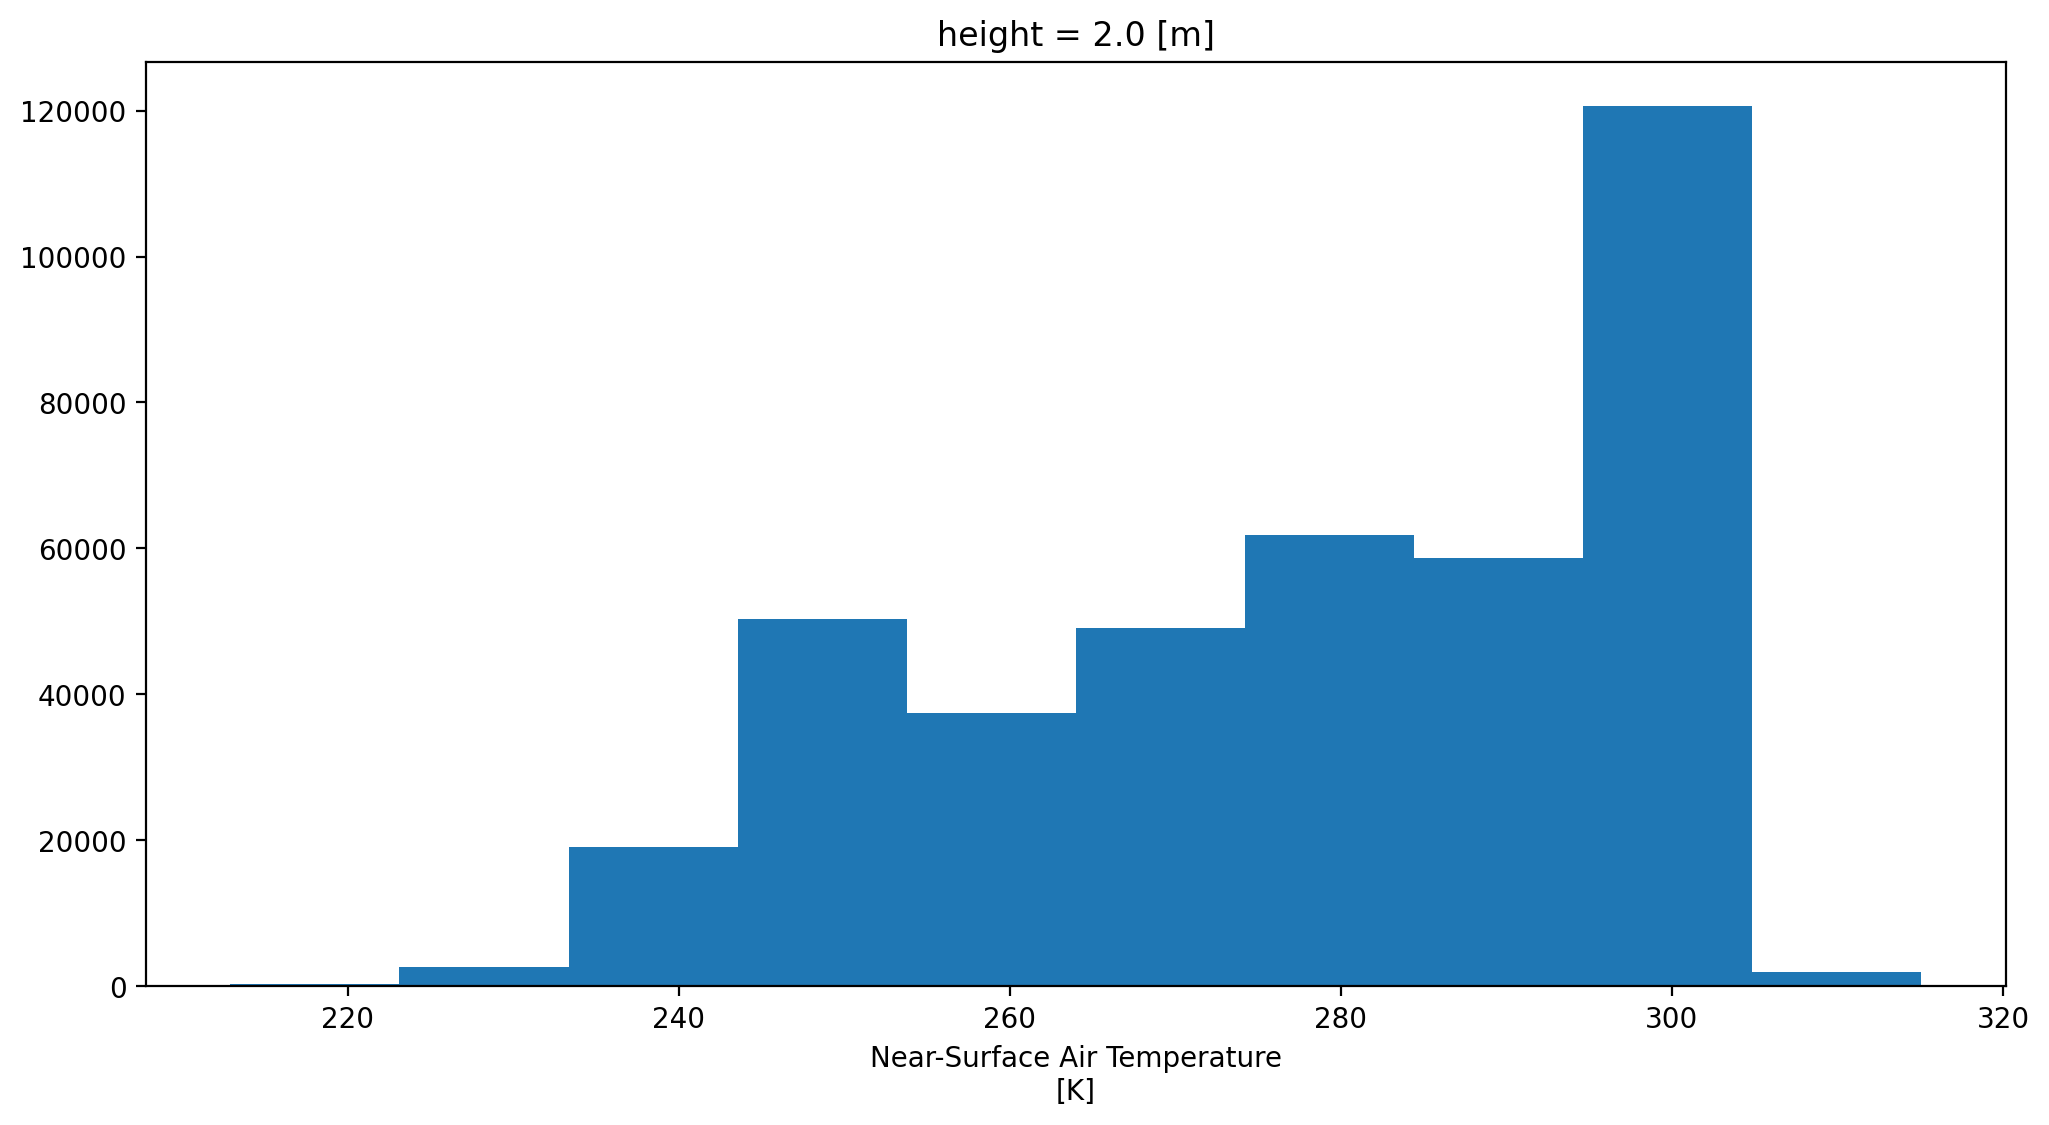

In [ ]:
ds_day_ssp126.tas.sel(time='2020-01').squeeze().plot()

(array([   261.,   2639.,  19000.,  50260.,  37463.,  49076.,  61859.,
         58675., 120642.,   1885.]),
 array([212.90377808, 223.11994934, 233.33612061, 243.55227661,
        253.76844788, 263.98461914, 274.20080566, 284.41696167,
        294.63311768, 304.8493042 , 315.06546021]),
 <BarContainer object of 10 artists>)

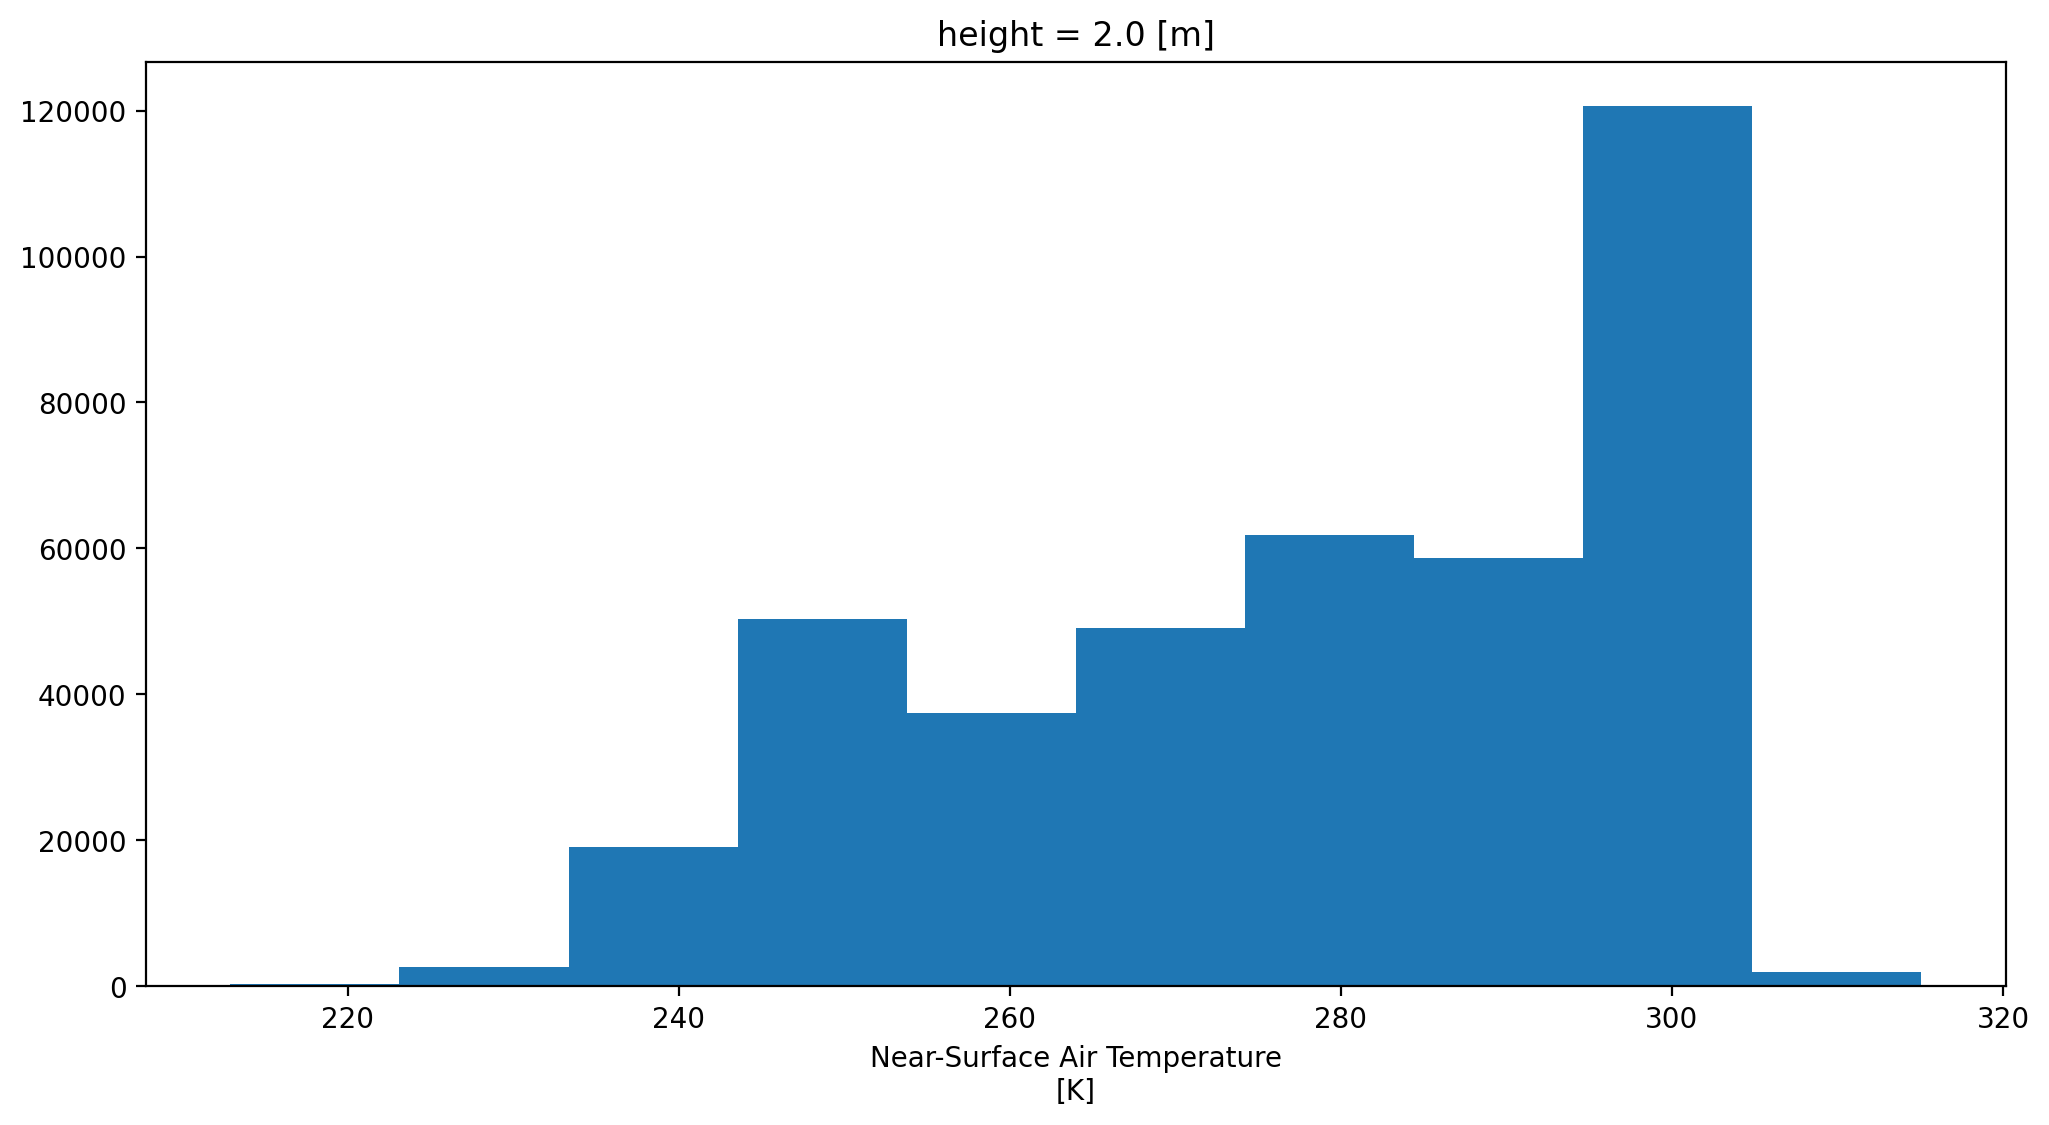

In [ ]:
ds_day_ssp245.tas.sel(time='2020-01').squeeze().plot()

(array([   309.,   4607.,  31999.,  42399.,  27320.,  39802.,  65379.,
         57823., 123126.,   8996.]),
 array([212.82806396, 222.92492676, 233.02180481, 243.1186676 ,
        253.21554565, 263.31240845, 273.40927124, 283.50613403,
        293.60302734, 303.69989014, 313.79675293]),
 <BarContainer object of 10 artists>)

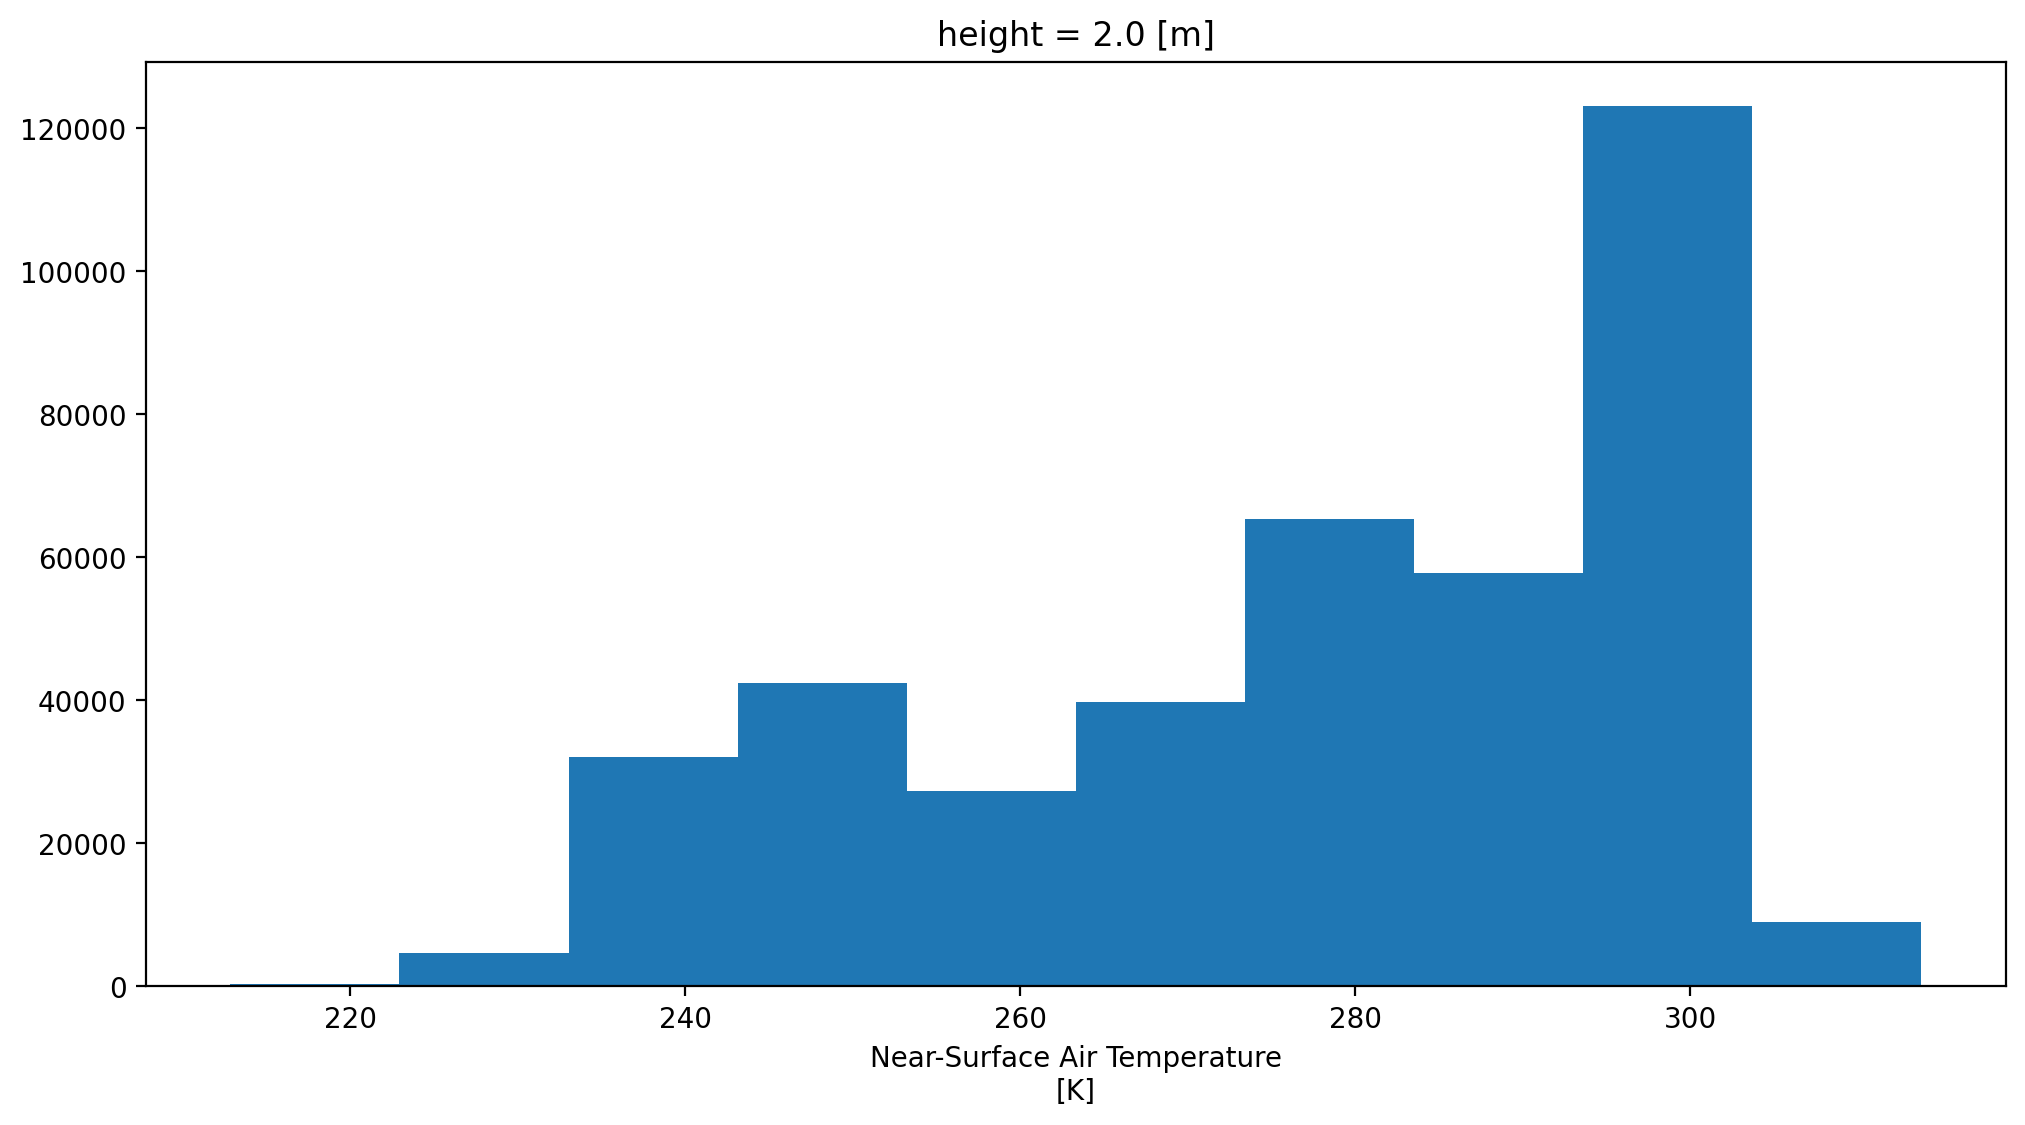

In [109]:
ds_day_ssp585.tas.sel(time='2020-01').squeeze().plot()

With the bar chart, is is very hard to understand the difference at one glance. And its kind of plain...